In [1]:
import json
import numpy as np
from pathlib import Path

data_folder = Path("../data")

with open(data_folder / "grid.json") as file:
    grid = json.load(file)

with open(data_folder / "hovmoller.json") as file:
    hov = json.load(file)

# Restore temperature anomalies from the scaled integers.
hov_values = np.array(hov["values"], dtype=float) * hov["scale"]

print("Map grid:", len(grid["lat"]), "latitudes ×",
      len(grid["lon"]), "longitudes")
print("Heatmap shape:", hov_values.shape)
print("Date range:", hov["dates"][0], "to", hov["dates"][-1])


Map grid: 48 latitudes × 72 longitudes
Heatmap shape: (780, 68)
Date range: 1950-01 to 2014-12


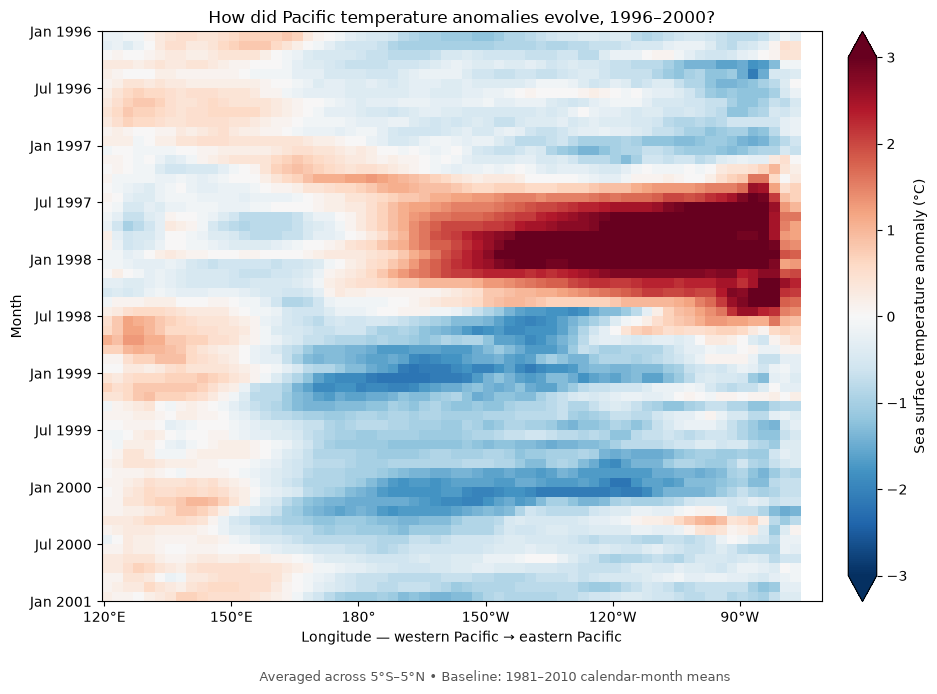

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Select January 1996 through December 2000.
dates = pd.to_datetime(hov["dates"])
longitudes = np.array(hov["lon"])

selected = (dates >= "1996-01-01") & (dates < "2001-01-01")

selected_dates = dates[selected]
selected_values = hov_values[selected]

# Construct month boundaries so each row represents a full month.
date_edges = pd.date_range(
    start=selected_dates[0],
    end=selected_dates[-1] + pd.offsets.MonthBegin(1),
    freq="MS"
)

# Construct longitude boundaries from the grid-cell centers.
lon_edges = np.concatenate([
    [longitudes[0] - (longitudes[1] - longitudes[0]) / 2],
    (longitudes[:-1] + longitudes[1:]) / 2,
    [longitudes[-1] + (longitudes[-1] - longitudes[-2]) / 2]
])

fig, ax = plt.subplots(figsize=(10, 7))

# Red indicates warmer conditions; blue indicates cooler conditions.
# The symmetric scale keeps zero at the center.
im = ax.pcolormesh(
    lon_edges,
    mdates.date2num(date_edges),
    np.ma.masked_invalid(selected_values),
    cmap="RdBu_r",
    vmin=-3,
    vmax=3,
    shading="flat",
    rasterized=True
)

# Display earlier dates at the top.
ax.invert_yaxis()
ax.yaxis_date()
ax.yaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.yaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# Convert the 0–360 longitude convention into familiar labels.
ax.set_xticks([120, 150, 180, 210, 240, 270])
ax.set_xticklabels([
    "120°E", "150°E", "180°", "150°W", "120°W", "90°W"
])

ax.set(
    title="How did Pacific temperature anomalies evolve, 1996–2000?",
    xlabel="Longitude — western Pacific → eastern Pacific",
    ylabel="Month"
)

colorbar = fig.colorbar(im, ax=ax, pad=0.03, extend="both")
colorbar.set_label("Sea surface temperature anomaly (°C)")

fig.text(
    0.5, 0.02,
    "Averaged across 5°S–5°N • Baseline: 1981–2010 calendar-month means",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

We could expand this to longer periods by using a time slider instead and ticks for certain anomolies we are aware of

## Viz 2: Pacific Temperature anomolies by Month 
interactive aspect could be rotating through months or isolating lines 

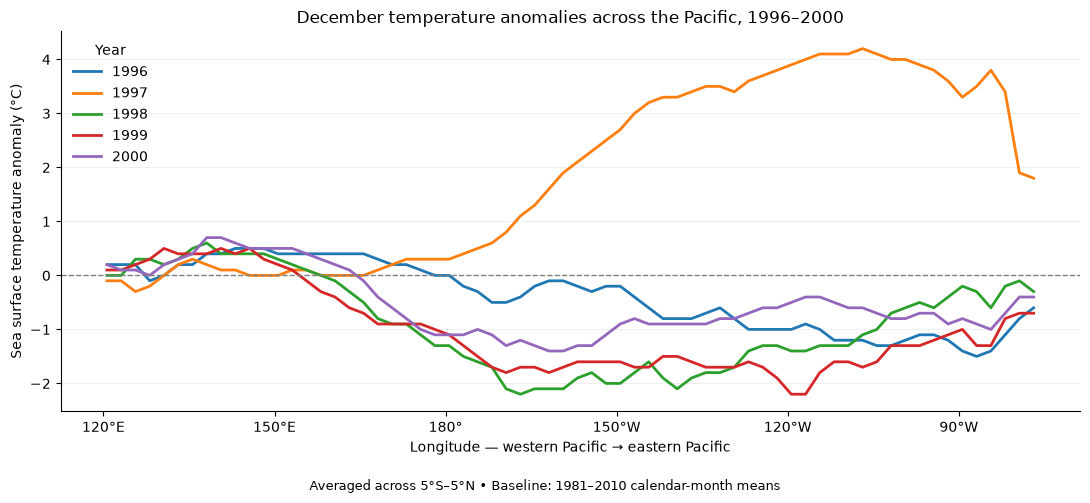

In [3]:
dates = pd.to_datetime(hov["dates"])
longitudes = np.array(hov["lon"])

fig, ax = plt.subplots(figsize=(11, 5))

for year in range(1996, 2001):
    selected = (dates.year == year) & (dates.month == 12)

    if selected.any():
        ax.plot(
            longitudes,
            hov_values[selected][0],
            label=str(year),
            linewidth=2
        )

ax.axhline(0, color="gray", linestyle="--", linewidth=1)

ax.set_xticks([120, 150, 180, 210, 240, 270])
ax.set_xticklabels([
    "120°E", "150°E", "180°", "150°W", "120°W", "90°W"
])

ax.set(
    title="December temperature anomalies across the Pacific, 1996–2000",
    xlabel="Longitude — western Pacific → eastern Pacific",
    ylabel="Sea surface temperature anomaly (°C)"
)

ax.legend(title="Year", frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.01,
    "Averaged across 5°S–5°N • Baseline: 1981–2010 calendar-month means",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

# Viz 3: Comparison of three regions
interactivity could be comparing point by point on at certain years
Colors could be changed

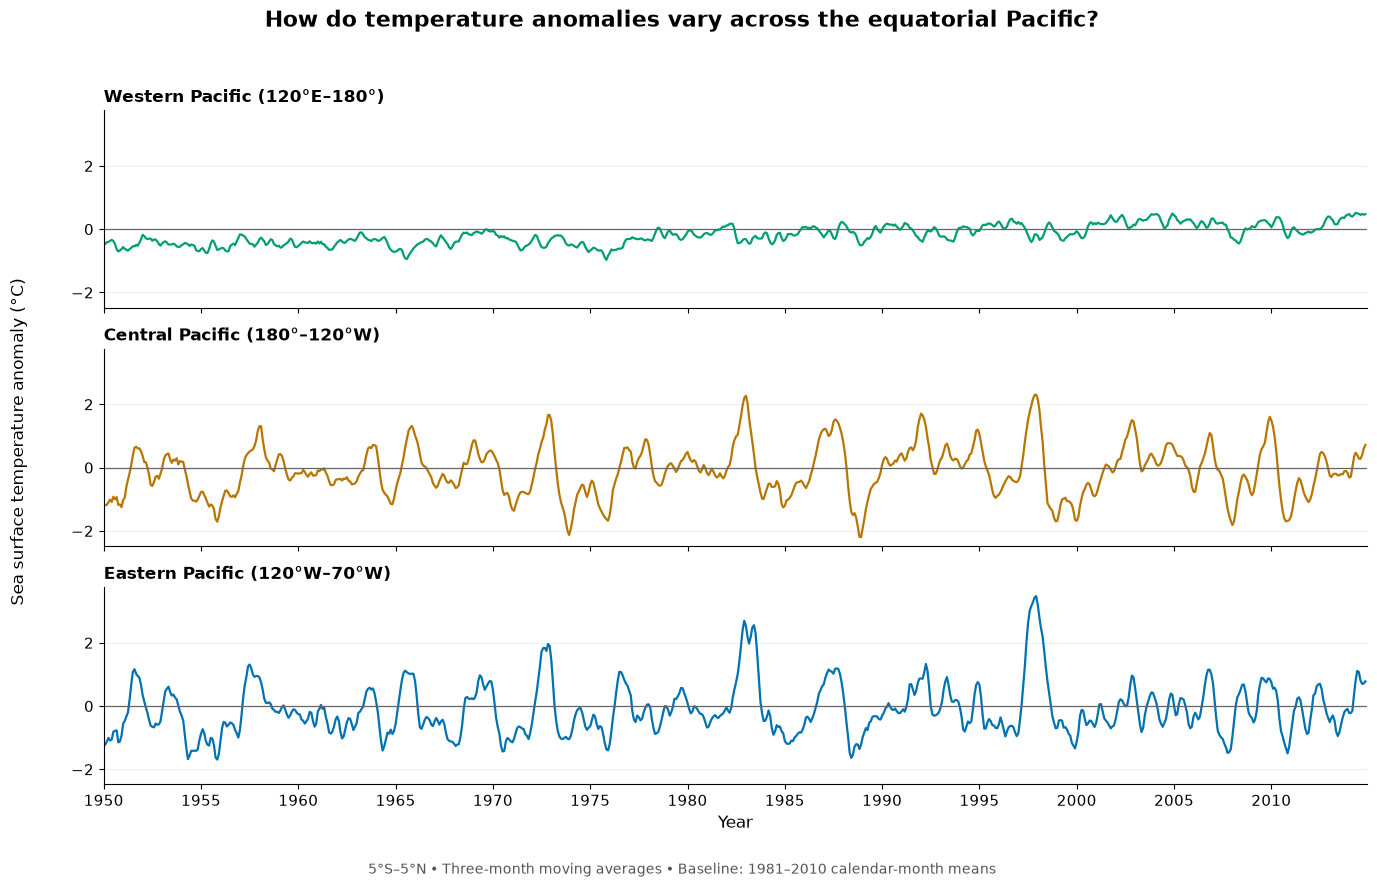

In [4]:
dates = pd.to_datetime(hov["dates"])
longitudes = np.array(hov["lon"])

regions = {
    "Western Pacific (120°E–180°)": (120, 180, "#009E73"),
    "Central Pacific (180°–120°W)": (180, 240, "#B87500"),
    "Eastern Pacific (120°W–70°W)": (240, 290, "#0072B2")
}

# Shared axes keep comparisons consistent across all three panels.
fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 9),
    sharex=True,
    sharey=True
)

for ax, (label, (west, east, color)) in zip(axes, regions.items()):
    selected = (longitudes >= west) & (longitudes < east)

    regional = pd.Series(
        np.nanmean(hov_values[:, selected], axis=1),
        index=dates
    )

    smoothed = regional.rolling(window=3, center=True).mean()

    ax.plot(
        smoothed.index,
        smoothed,
        color=color,
        linewidth=1.6
    )

    ax.axhline(0, color="#666666", linewidth=0.9)

    # Direct panel labels replace the legend.
    ax.set_title(label, loc="left", fontsize=12, fontweight="bold")
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=11)

axes[-1].set_xlim(dates.min(), dates.max())
axes[-1].xaxis.set_major_locator(mdates.YearLocator(5))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[-1].set_xlabel("Year", fontsize=12)

fig.supylabel("Sea surface temperature anomaly (°C)", fontsize=12)

fig.suptitle(
    "How do temperature anomalies vary across the equatorial Pacific?",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5, 0.02,
    "5°S–5°N • Three-month moving averages • "
    "Baseline: 1981–2010 calendar-month means",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(rect=[0.03, 0.05, 1, 0.95])
plt.show()

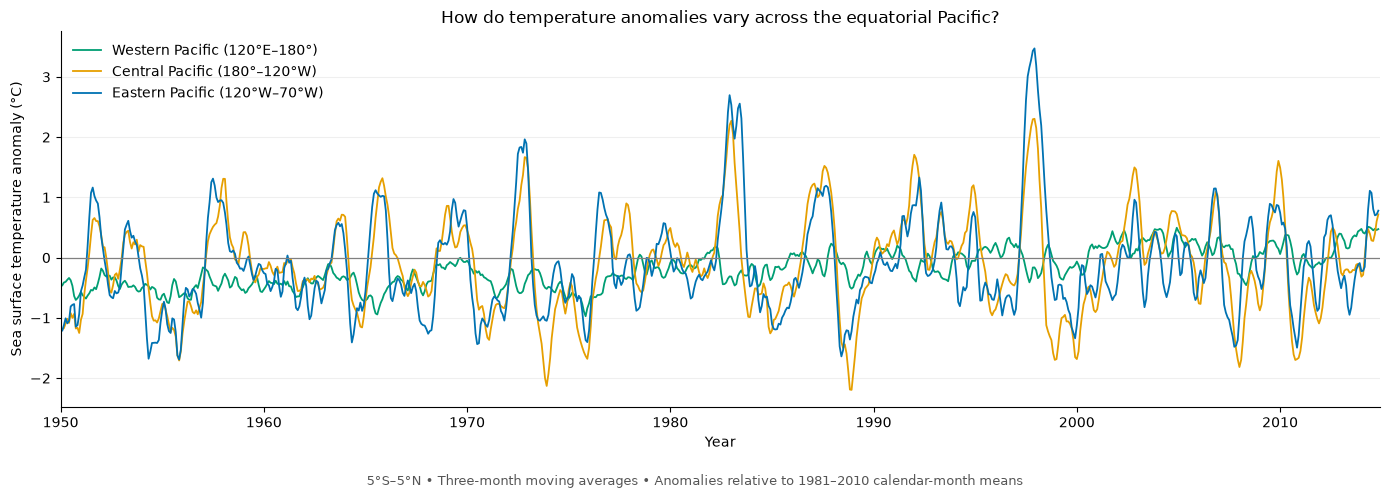

In [5]:
dates = pd.to_datetime(hov["dates"])
longitudes = np.array(hov["lon"])

# Three non-overlapping longitude bands for comparison.
regions = {
    "Western Pacific (120°E–180°)": (120, 180, "#009E73"),
    "Central Pacific (180°–120°W)": (180, 240, "#E69F00"),
    "Eastern Pacific (120°W–70°W)": (240, 290, "#0072B2")
}

fig, ax = plt.subplots(figsize=(14, 5))

for label, (west, east, color) in regions.items():
    selected = (longitudes >= west) & (longitudes < east)

    # Average the available longitude cells within each region.
    regional = pd.Series(
        np.nanmean(hov_values[:, selected], axis=1),
        index=dates
    )

    # Smooth monthly variation with a centered three-month average.
    smoothed = regional.rolling(window=3, center=True).mean()

    ax.plot(
        smoothed.index,
        smoothed,
        label=label,
        color=color,
        linewidth=1.3
    )

ax.axhline(0, color="gray", linewidth=0.9)

ax.set(
    title="How do temperature anomalies vary across the equatorial Pacific?",
    xlabel="Year",
    ylabel="Sea surface temperature anomaly (°C)",
    xlim=(dates.min(), dates.max())
)

ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.02,
    "5°S–5°N • Three-month moving averages • "
    "Anomalies relative to 1981–2010 calendar-month means",
    ha="center",
    fontsize=9,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

# Disregard from here down

In [ ]:
events = pd.read_csv("../data/events.csv")
nino34 = pd.read_csv("../data/nino34.csv")

display(events.head())
display(nino34.head(20))

,phase,start,end,peak
0,La Niña,1950-02,1951-03,-1.24
1,El Niño,1951-08,1951-12,0.77
2,La Niña,1954-05,1957-01,-1.75
3,El Niño,1957-06,1958-04,1.36
4,El Niño,1963-07,1964-01,0.84


,date,year,month,nino34,oni,phase
0,1950-01,1950,1,-1.07,NaN,Neutral
1,1950-02,1950,2,-1.55,-1.24,La Niña
2,1950-03,1950,3,-1.10,-1.20,La Niña
3,1950-04,1950,4,-0.94,-1.12,La Niña
4,1950-05,1950,5,-1.32,-1.06,La Niña
5,1950-06,1950,6,-0.92,-1.11,La Niña
6,1950-07,1950,7,-1.10,-0.89,La Niña
7,1950-08,1950,8,-0.66,-0.96,La Niña
8,1950-09,1950,9,-1.12,-0.89,La Niña
9,1950-10,1950,10,-0.88,-1.15,La Niña


In [2]:
nino34["date"] = pd.to_datetime(nino34["date"])

events["start"] = pd.to_datetime(events["start"])
events["end"] = pd.to_datetime(events["end"])

# Count both the starting and ending months.
events["duration_months"] = (
    (events["end"].dt.year - events["start"].dt.year) * 12
    + events["end"].dt.month
    - events["start"].dt.month
    + 1
)

events["peak_magnitude"] = events["peak"].abs()

display(events.head())

,phase,start,end,peak,duration_months,peak_magnitude
0,La Niña,1950-02-01,1951-03-01,-1.24,14,1.24
1,El Niño,1951-08-01,1951-12-01,0.77,5,0.77
2,La Niña,1954-05-01,1957-01-01,-1.75,33,1.75
3,El Niño,1957-06-01,1958-04-01,1.36,11,1.36
4,El Niño,1963-07-01,1964-01-01,0.84,7,0.84


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

monthly = nino34.copy()
event_data = events.copy()

#Convert to datetime and sort
monthly["date"] = pd.to_datetime(monthly["date"])
monthly = monthly.sort_values("date")

#Convert to datetime and sort
event_data["start"] = pd.to_datetime(event_data["start"])
event_data["end"] = pd.to_datetime(event_data["end"])

# Include both the starting and ending months
event_data["duration_months"] = (
    (event_data["end"].dt.year - event_data["start"].dt.year) * 12
    + event_data["end"].dt.month
    - event_data["start"].dt.month
    + 1
)

# Compare strength while keeping the original signed peak.
event_data["peak_magnitude"] = event_data["peak"].abs()

#Colors defined
colors = {
    "El Niño": "#D55E00",
    "La Niña": "#0072B2"
}

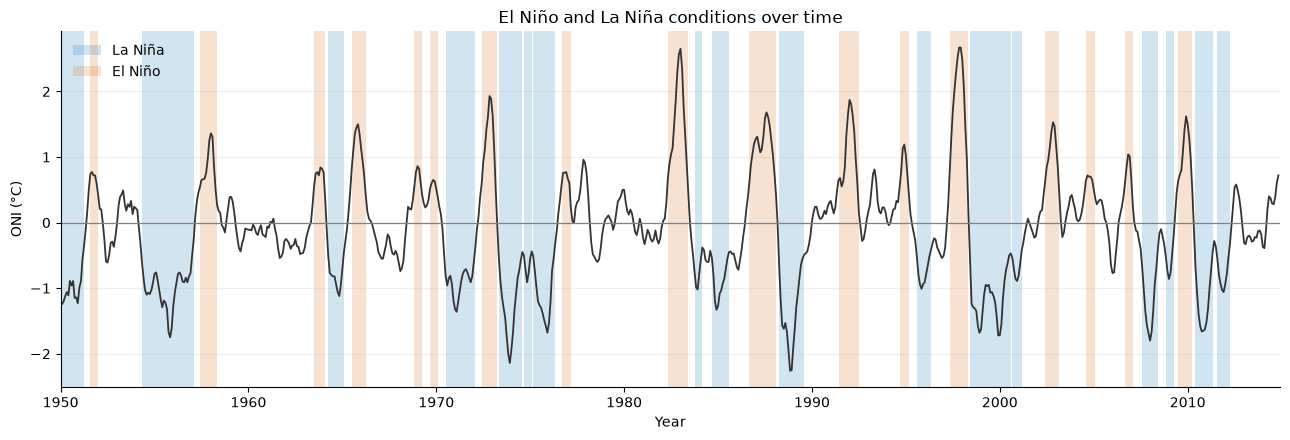

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4.5))

# Shade each event's full interval
labeled_phases = set()

for _, event in event_data.iterrows():
    phase = event["phase"]

    if phase not in colors:
        continue

    label = phase if phase not in labeled_phases else "_nolegend_"

    ax.axvspan(
        event["start"],
        event["end"] + pd.offsets.MonthBegin(1),
        color=colors[phase],
        alpha=0.18,
        linewidth=0,
        label=label
    )

    labeled_phases.add(phase)

# Missing index values remain gaps in the line.
ax.plot(
    monthly["date"],
    monthly["oni"],
    color="#333333",
    linewidth=1.3
)

ax.axhline(0, color="gray", linewidth=0.9)

ax.set(
    title="El Niño and La Niña conditions over time",
    xlabel="Year",
    ylabel="ONI (°C)",
    xlim=(monthly["date"].min(), monthly["date"].max())
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

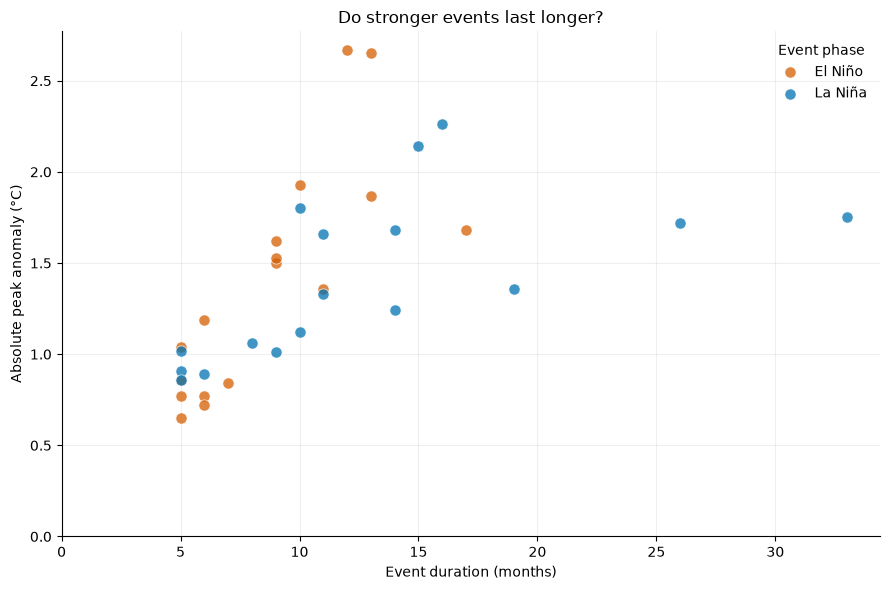

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))

for phase, color in colors.items():
    subset = event_data.loc[event_data["phase"] == phase]

    ax.scatter(
        subset["duration_months"],
        subset["peak_magnitude"],
        color=color,
        label=phase,
        s=65,
        alpha=0.75,
        edgecolors="white",
        linewidths=0.6
    )

ax.set(
    title="Do stronger events last longer?",
    xlabel="Event duration (months)",
    ylabel="Absolute peak anomaly (°C)"
)

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.legend(title="Event phase", frameon=False)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()